# CMSC320: Checkpoint 2

In [115]:
# imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")

In [116]:
# get only the columns we will use
cols = ['code', 'product_name', 'countries_en', 'pnns_groups_1', 'nutrition_grade_fr',
        'energy_100g', 'fat_100g', 'saturated-fat_100g', 'sugars_100g', 'proteins_100g', 'salt_100g']
df = pd.read_csv('en.openfoodfacts.org.products.tsv', sep='\t', usecols=cols, low_memory=False)

print("Shape:", df.shape)
df.head()

Shape: (356027, 11)


,code,product_name,countries_en,nutrition_grade_fr,pnns_groups_1,energy_100g,fat_100g,saturated-fat_100g,sugars_100g,proteins_100g,salt_100g
0,3087,Farine de blé noir,France,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,4530,Banana Chips Sweetened (Whole),United States,d,NaN,2243.0,28.57,28.57,14.29,3.57,0.00000
2,4559,Peanuts,United States,b,NaN,1941.0,17.86,0.00,17.86,17.86,0.63500
3,16087,Organic Salted Nut Mix,United States,d,NaN,2540.0,57.14,5.36,3.57,17.86,1.22428
4,16094,Organic Polenta,United States,NaN,NaN,1552.0,1.43,NaN,NaN,8.57,NaN


In [117]:
# convert nutrient columns to numeric type
nutrient_cols = ['energy_100g', 'fat_100g', 'saturated-fat_100g', 'sugars_100g', 'proteins_100g', 'salt_100g']
df[nutrient_cols] = df[nutrient_cols].apply(pd.to_numeric, errors='coerce')

# drop duplicate products or missing/impossible values for sugar and energy
df = df.drop_duplicates(subset='code')
df = df.dropna(subset=['sugars_100g', 'energy_100g'])
df = df[df['sugars_100g'].between(0, 100) & df['energy_100g'].between(0, 3800)]

# normalize nutrition grades and food group labels
# e.g. "salty-snacks" to "Salty snacks"
df['nutrition_grade_fr'] = df['nutrition_grade_fr'].str.lower()
df = df[df['nutrition_grade_fr'].isin(list('abcde'))].copy()
df['pnns_groups_1'] = df['pnns_groups_1'].str.replace('-', ' ').str.capitalize()

print("Updated shape after parsing and cleaning:", df.shape)

Updated shape after parsing and cleaning: (254346, 11)


In [118]:
# data exploration
display(df.dtypes.to_frame('dtype'))
display(df[nutrient_cols].describe())

# How many entries and features are there?
print(f"Entries: {df.shape[0]}")
print(f"Features: {df.shape[1]}")

# How much data is missing?
print("\nMissing values per feature:")
print(df.isna().mean().sort_values(ascending=False).round(5).to_string())
print("The food group 'pnns_groups_1' is missing for about 61% of the products.")

,dtype
code,object
product_name,str
countries_en,str
nutrition_grade_fr,str
pnns_groups_1,str
energy_100g,float64
fat_100g,float64
saturated-fat_100g,float64
sugars_100g,float64
proteins_100g,float64


,energy_100g,fat_100g,saturated-fat_100g,sugars_100g,proteins_100g,salt_100g
count,254346.000000,238515.000000,254346.000000,254346.000000,254346.000000,254346.000000
mean,1168.126808,13.341647,4.944272,14.801780,7.787663,1.591109
std,762.143521,16.251018,7.518054,19.744455,8.225069,128.193583
min,0.000000,0.000000,0.000000,0.000000,-3.570000,0.000000
25%,448.000000,0.880000,0.000000,1.200000,1.770000,0.100000
50%,1168.000000,7.140000,1.790000,5.000000,5.700000,0.622300
75%,1703.000000,21.430000,7.140000,22.500000,10.710000,1.348740
max,3782.000000,200.000000,100.000000,100.000000,305.000000,64312.800000


Entries: 254346
Features: 11

Missing values per feature:
pnns_groups_1         0.61423
fat_100g              0.06224
product_name          0.01093
countries_en          0.00023
code                  0.00000
nutrition_grade_fr    0.00000
energy_100g           0.00000
saturated-fat_100g    0.00000
sugars_100g           0.00000
proteins_100g         0.00000
salt_100g             0.00000
The food group 'pnns_groups_1' is missing for about 61% of the products.


In [119]:
# build a separate exploded table 
df_country = df.assign(country=df['countries_en'].str.split(',')).explode('country')
df_country['country'] = df_country['country'].str.strip()

# view 'sugars_100g' statistics per country
stats_by_country = df_country.groupby('country')['sugars_100g'].describe()
display(stats_by_country[stats_by_country['count'] >= 100].sort_values('mean', ascending=False).head(10))

# Are any categories over-represented?
print("\nTop 5 countries by number of products:")
print(df_country['country'].value_counts().head(5).to_string())
print("The United States and France account for over 90% of the products.")

,count,mean,std,min,25%,50%,75%,max
country,,,,,,,,
Netherlands,364.0,18.797308,22.806128,0.0,2.0750,6.80,33.000,100.0
Denmark,189.0,17.461111,20.901915,0.0,1.5000,5.90,35.000,81.9
Canada,248.0,16.426650,19.603588,0.0,2.3875,8.00,24.250,85.7
Belgium,1536.0,16.033827,19.630940,0.0,2.0000,6.73,25.925,100.0
United States,139205.0,15.808232,20.167745,0.0,1.6300,6.06,25.000,100.0
Switzerland,10796.0,15.518554,19.655696,0.0,1.5000,5.00,24.900,100.0
United Kingdom,2142.0,15.264403,21.156921,0.0,1.2000,4.60,22.100,100.0
Germany,5539.0,14.720785,19.563403,0.0,1.5000,4.80,21.400,100.0
Portugal,502.0,14.547968,17.469899,0.0,2.2000,6.10,22.800,99.7



Top 5 countries by number of products:
country
United States    139205
France            93198
Switzerland       10796
Germany            5539
Spain              2997
The United States and France account for over 90% of the products.


Outlier border = 54.45g
Number of outliers: 15,872 of 254,346 (6.24%)
Skew = 1.70


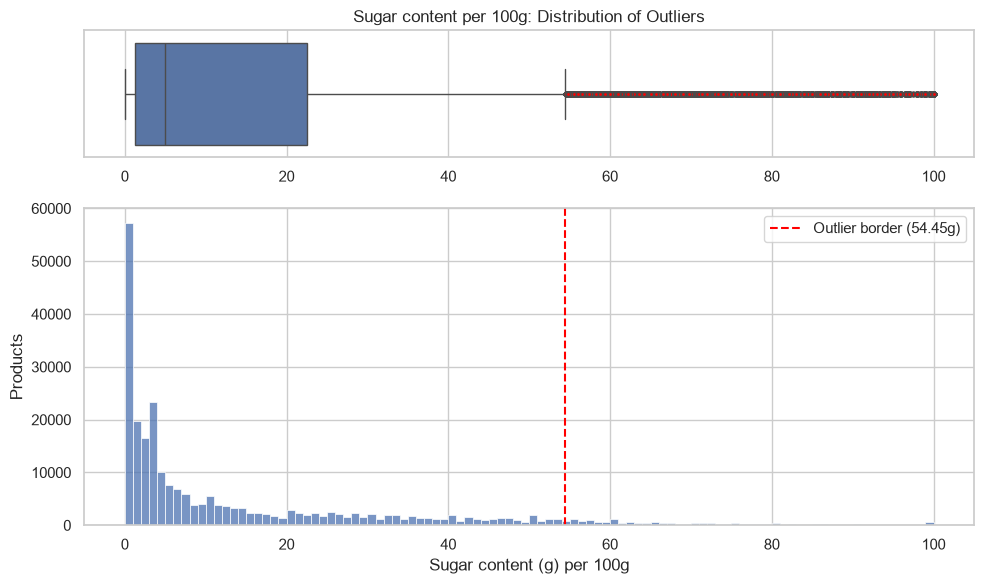

Sugar content is strongly right-skewed
Most products have little sugar, but a long tail of very sugary products is flagged as outliers.
These include real products like candy or syrups, so we keep them.


In [120]:
# show outlier detection and distribution with box plot and histogram
# Interquartile Range (IQR = Q3 - Q1) Rule: a value is an outlier if it lies above Q3 + 1.5*IQR

# calculate outlier information
sugar = df['sugars_100g']
q1, q3 = sugar.quantile([0.25, 0.75])
outlier_border = q3 + 1.5 * (q3 - q1)
n_outliers = (sugar > outlier_border).sum()
print(f"Outlier border = {outlier_border:.2f}g")
print(f"Number of outliers: {n_outliers:,} of {len(sugar):,} ({n_outliers / len(sugar):.2%})")
print(f"Skew = {sugar.skew():.2f}")

# plot outliers
fig, axes = plt.subplots(2, 1, figsize=(10, 6), gridspec_kw={'height_ratios': [1, 2.5]})
sns.boxplot(x=sugar, ax=axes[0], flierprops=dict(marker='o', markersize=3, markerfacecolor='red'))
axes[0].set(title='Sugar content per 100g: Distribution of Outliers', xlabel='')

sns.histplot(sugar, bins=100, ax=axes[1])
axes[1].axvline(outlier_border, color='red', ls='--', label=f'Outlier border ({outlier_border:.2f}g)')
axes[1].set(xlabel='Sugar content (g) per 100g', ylabel='Products'); axes[1].legend()
plt.tight_layout()
plt.show()

# conclusion
print("Sugar content is strongly right-skewed")
print("Most products have little sugar, but a long tail of very sugary products is flagged as outliers.")
print("These include real products like candy or syrups, so we keep them.")

nutrition_grade_fr,a,b,c,d,e
countries_en,,,,,
Australia,84,108,96,118,89
Netherlands,42,20,45,91,52


chi2 = 28.67
dof = 4
p = 9.1e-06
Smallest expected count = 42.28


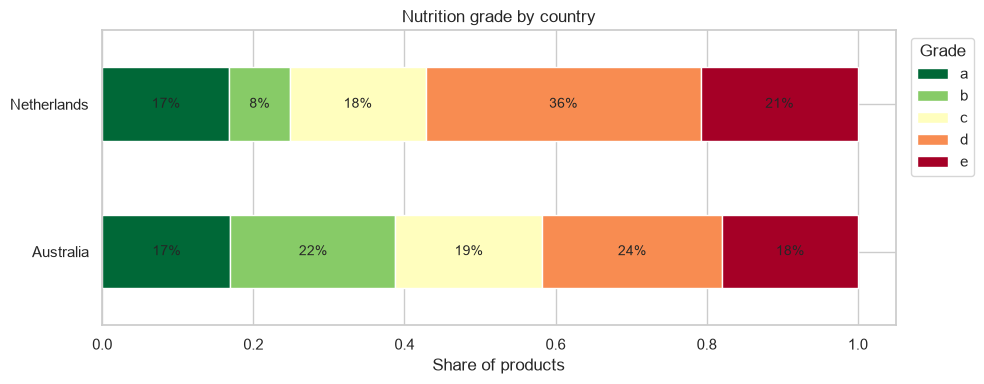

p = 9.1e-06 < 0.05, so reject the H0.
Nutrition grade depends on country.
Dutch products skew less healthy with 57% graded D or E compared to 42% of Australian products.
Also, only 8% of Dutch products are graded B compared with 22% of Australian products.


In [121]:
# chi-squared test

# using categorical data: country and nutrition grade
# chose to compare products only sold in the countries Netherlands and Australia

# Ho: Nutrition grade and country are independent.
# Ha: Nutrition grade and country are not independent.

country_cols = df[df['countries_en'].isin(['Netherlands', 'Australia'])]
table = pd.crosstab(country_cols['countries_en'], country_cols['nutrition_grade_fr'])
chi2, p_chi, dof, expected = stats.chi2_contingency(table)

display(table)
print(f"chi2 = {chi2:.2f}")
print(f"dof = {dof}")
print(f"p = {p_chi:.3g}")
print(f"Smallest expected count = {expected.min():.2f}")

props = pd.crosstab(country_cols['countries_en'], country_cols['nutrition_grade_fr'], normalize='index')
ax = props.plot.barh(stacked=True, colormap='RdYlGn_r', figsize=(10, 4))
for c in ax.containers:
    ax.bar_label(c, labels=[f'{v:.0%}' if v > 0.05 else '' for v in c.datavalues], label_type='center', fontsize=10)
ax.set(title=f'Nutrition grade by country', xlabel='Share of products', ylabel='')
ax.legend(title='Grade', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

# conclusion
print(f"p = {p_chi:.3g} < 0.05, so reject the H0.")
print("Nutrition grade depends on country.")
print("Dutch products skew less healthy with 57% graded D or E compared to 42% of Australian products.")
print("Also, only 8% of Dutch products are graded B compared with 22% of Australian products.")

t = 32.89
p = 5.09e-227


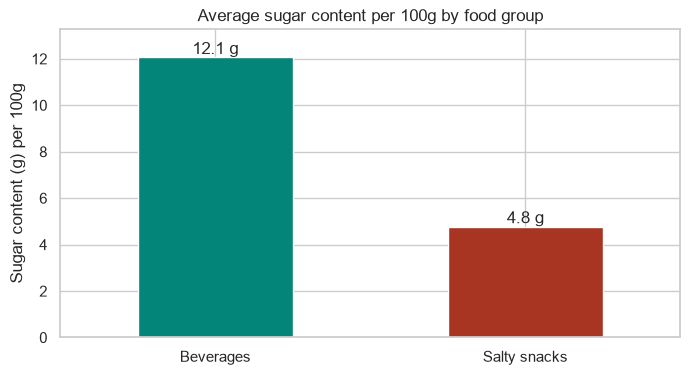

p = 5.09e-227 < 0.05 so reject the H0
The mean sugar content differs between beverages and salty snacks.
Beverages average 12.1g of sugar per 100g, compared to 4.8g average for salty snacks.


In [122]:
# t-test

# H0: Beverages and salty snacks have equal mean sugar content.
# Ha: Beverages and salty snacks have different mean sugar content.

beverages = df.loc[df['pnns_groups_1'] == 'Beverages', 'sugars_100g']
snacks = df.loc[df['pnns_groups_1'] == 'Salty snacks', 'sugars_100g']

t_stat, p_t = stats.ttest_ind(beverages, snacks, equal_var=False)
print(f"t = {t_stat:.2f}")
print(f"p = {p_t:.3g}")

means = pd.Series({'Beverages': beverages.mean(), 'Salty snacks': snacks.mean()})
ax = means.plot.bar(color=['#038579', '#A83522'], rot=0, figsize=(8, 4))
ax.bar_label(ax.containers[0], fmt='%.1f g')
ax.margins(y=0.1)
ax.set(title='Average sugar content per 100g by food group', ylabel='Sugar content (g) per 100g')
plt.show()

# conclusion
print(f"p = {p_t:.3g} < 0.05 so reject the H0")
print("The mean sugar content differs between beverages and salty snacks.")
print("Beverages average 12.1g of sugar per 100g, compared to 4.8g average for salty snacks.")